In [1]:
%pip install tensorflow
%pip install keras

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


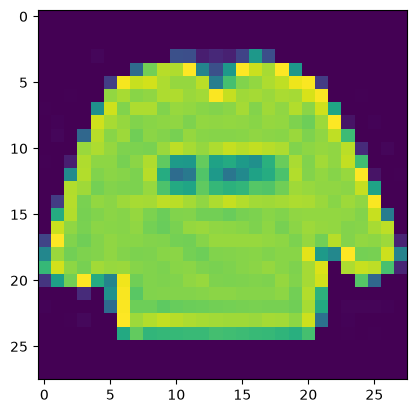

In [7]:
import pandas as pnd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
import keras

tf.config.set_visible_devices([], 'GPU')
LONGUEUR_IMAGE = 28
LARGEUR_IMAGE = 28
observations_entrainement = pnd.read_csv('datas/fashion-mnist_train.csv')

X = np.array(observations_entrainement.iloc[:, 1:])
premiereImage = X[0]
premiereImage = premiereImage.reshape([LONGUEUR_IMAGE, LARGEUR_IMAGE])
plt.imshow(premiereImage)
plt.show()

y = keras.utils.to_categorical(np.array(observations_entrainement.iloc[:,0]))
X_apprentissage, X_validation, y_apprentissage, y_validation = train_test_split(X, y, test_size=0.2, random_state=13)

X_apprentissage = X_apprentissage.reshape(X_apprentissage.shape[0], LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)
X_apprentissage = X_apprentissage.astype('float32')
X_apprentissage /= 255
X_validation = X_validation.reshape(X_validation.shape[0], LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)
X_validation = X_validation.astype('float32')
X_validation /= 255

observations_test = pnd.read_csv('datas/fashion-mnist_test.csv')
X_test = np.array(observations_test.iloc[:, 1:])
y_test = tf.keras.utils.to_categorical(np.array(observations_test.iloc[:, 0]))
X_test = X_test.reshape(X_test.shape[0], LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)
X_test = X_test.astype('float32')
X_test /= 255

Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.8135 - loss: 0.5373 - val_accuracy: 0.8662 - val_loss: 0.3912
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8723 - loss: 0.3603 - val_accuracy: 0.8704 - val_loss: 0.3590
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8873 - loss: 0.3165 - val_accuracy: 0.8857 - val_loss: 0.3254
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8953 - loss: 0.2943 - val_accuracy: 0.8889 - val_loss: 0.3061
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9030 - loss: 0.2728 - val_accuracy: 0.8888 - val_loss: 0.3059
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9082 - loss: 0.2551 - val_accuracy: 0.9045 - val_loss: 0.2687
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9137 - loss: 0.2384 - val_accuracy: 0.8994 - val_loss: 0.2827
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9201 - loss: 0.2243 - val_accuracy: 0.

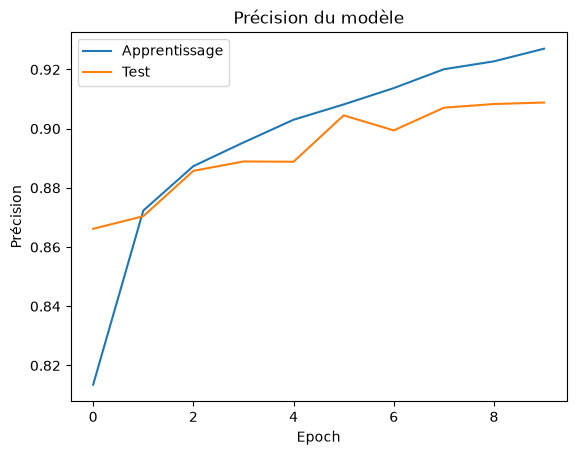

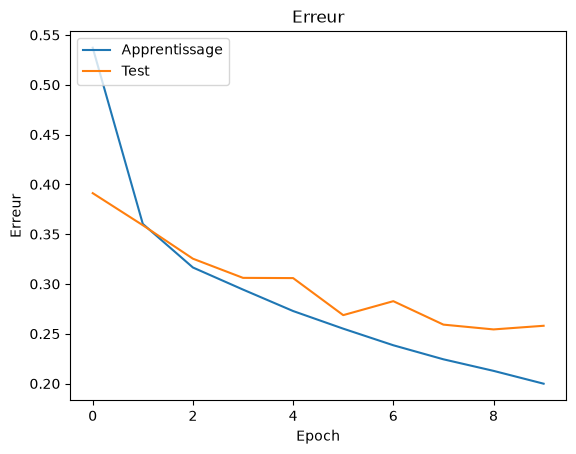

In [11]:
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Input
from keras.layers import Conv2D, MaxPooling2D

dimentionImage = (LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)
reseauNeurone1Convolution = Sequential()
reseauNeurone1Convolution.add(Input(shape=dimentionImage))
reseauNeurone1Convolution.add(Conv2D(32, kernel_size=(3, 3), activation='relu'))
reseauNeurone1Convolution.add(MaxPooling2D(pool_size=(2, 2)))
reseauNeurone1Convolution.add(Dropout(0.2))
reseauNeurone1Convolution.add(Flatten())
reseauNeurone1Convolution.add(Dense(128, activation='relu'))
reseauNeurone1Convolution.add(Dense(10, activation='softmax'))

reseauNeurone1Convolution.compile(loss=keras.losses.categorical_crossentropy, optimizer=tf.keras.optimizers.Adam(), metrics=['accuracy'])

historique_apprentissage = reseauNeurone1Convolution.fit(X_apprentissage, y_apprentissage, batch_size=256, epochs=10, verbose=1, 
                                                         validation_data=(X_validation, y_validation))

evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)
print('Erreur: ', evaluation[0])
print('Précision: ', evaluation[1])

plt.plot(historique_apprentissage.history['accuracy'])
plt.plot(historique_apprentissage.history['val_accuracy'])
plt.title('Précision du modèle')
plt.ylabel('Précision')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()
plt.plot(historique_apprentissage.history['loss'])
plt.plot(historique_apprentissage.history['val_loss'])
plt.title('Erreur')
plt.ylabel('Erreur')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()

In [14]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

generateur_images = tf.keras.preprocessing.image.ImageDataGenerator(rotation_range=8, width_shift_range=0.08, shear_range=0.3,
                                                                    height_shift_range=0.08, zoom_range=0.08)

nouvelles_images_apprentissage = generateur_images.flow(X_apprentissage, y_apprentissage, batch_size=256)
nouvelles_images_validation = generateur_images.flow(X_validation, y_validation, batch_size=256)
historique_apprentissage = reseauNeurone1Convolution.fit(nouvelles_images_apprentissage, steps_per_epoch=48000//256, epochs=50,
                                                         validation_data=nouvelles_images_validation, validation_steps=12000//256, verbose=1)
evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)
print('Erreur : ', evaluation[0])
print('Précision: ', evaluation[1])

model_json = reseauNeurone1Convolution.to_json()
with open("modele/modele.json", "w") as json_file:
    json_file.write(model_json)
reseauNeurone1Convolution.save_weights("modele/modele.weights.h5")
print("Modèle sauvegardé !")

Epoch 1/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - accuracy: 0.9084 - loss: 0.2458 - val_accuracy: 0.9005 - val_loss: 0.2764
Epoch 2/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9375 - loss: 0.1797 - val_accuracy: 0.9029 - val_loss: 0.2666
Epoch 3/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - accuracy: 0.9075 - loss: 0.2456 - val_accuracy: 0.8986 - val_loss: 0.2776
Epoch 4/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9062 - loss: 0.2013 - val_accuracy: 0.9011 - val_loss: 0.2736
Epoch 5/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - accuracy: 0.9092 - loss: 0.2460 - val_accuracy: 0.8989 - val_loss: 0.2699
Epoch 6/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9102 - loss: 0.2089 - val_accuracy: 0.8995 - val_loss: 0.2725
Epoch 7/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - accuracy: 0.9087 - loss: 0.2425 - val_accuracy: 0.9004 - val_loss: 0.2718
Epoch 8/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9141 - loss: 0.2474 - val_accuracy

In [ ]:
from keras.layers import BatchNormalization

reseauNeurones4Convolution = Sequential()
reseauNeurones4Convolution.add(Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=dimentionImage))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Conv2D(32, kernel_size=(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(MaxPooling2D(pool_size=(2, 2)))
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Conv2D(64, kernel_size=(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.25))